In the previous module, we assembled the complete Transformer — stacking Encoder and Decoder layers, wiring up masking, and training the model end-to-end with teacher forcing. During training, the Decoder always received the correct previous token as input. At **inference time**, there are no gold-standard tokens to hand: the model must generate translations entirely from its own predictions, one token at a time.

In this module, we will implement **autoregressive greedy decoding**, train a Transformer on Portuguese-to-English data, and run a live translation demo.

# Introduction

**Training (Teacher Forcing):** At each decoder step $t$, the model receives the ground-truth token $y_{t-1}$ regardless of what it predicted at step $t-1$. This creates a stable, efficient training signal — but it means the model never has to deal with its own mistakes.

**Inference (Autoregressive Decoding):** There are no ground-truth tokens. The model starts with a single `[START]` token and must predict all subsequent tokens using only its own previous outputs as context. Each prediction is fed back as input for the next step.

| Aspect | Training | Inference |
|---|---|---|
| Decoder input at step $t$ | Ground-truth token $y_{t-1}$ | Model's prediction $\hat{y}_{t-1}$ |
| How long it runs | Fixed — full target length | Until `[END]` or max length |
| Gradient flow | Yes | No |
| Speed | Parallel (all steps at once) | Sequential (one step at a time) |

# The Autoregressive Decoding Loop

At each step, the decoder predicts the **most probable next token** using a greedy argmax:

$$\hat{y}_t = \underset{v}{\arg \max}\; \text{softmax}\!\left(W_o \, h_t\right)$$

where $h_t$ is the decoder's hidden state at step $t$ and $W_o$ is the output projection matrix.

Greedy decoding always picks the single best token at each step. A more powerful but slower alternative, **beam search**, keeps the top-$k$ partial sequences at every step and selects the globally highest-probability complete translation. Real production systems (Google Translate, DeepL) use beam search with additional tricks like length penalty and coverage constraint. For this module, greedy decoding is sufficient to demonstrate the core idea.

```mermaid
sequenceDiagram
    participant E as Encoder
    participant D as Decoder
    participant O as Output
    Note over E: Source sentence encoded once
    E->>D: Encoder context (fixed)
    Note over D,O: Step 1
    D->>O: Input [START] → predict token_1
    O-->>D: Append token_1
    Note over D,O: Step 2
    D->>O: Input [START, token_1] → predict token_2
    O-->>D: Append token_2
    Note over D,O: Step N
    D->>O: Input grows by 1 each step
    O-->>D: Predict [END] → stop
```

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
import tensorflow_datasets as tfds

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

2026-10-25 08:45:01.699605: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792917901.970383      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792917902.047799      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792917902.817238      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792917902.817280      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792917902.817283      58 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: False


2026-10-25 08:45:34.859658: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
# Shared constants
VOCAB_SIZE   = 8000
BATCH_SIZE   = 64
MAX_LEN      = 40      # max source/target tokens (excl. [START]/[END])

# Tiny illustration model
TINY_LAYERS  = 1
TINY_D_MODEL = 32
TINY_HEADS   = 2
TINY_DFF     = 64
TINY_SAMPLES = 500
TINY_EPOCHS  = 30

# Full training model
FULL_LAYERS  = 2
FULL_D_MODEL = 128
FULL_HEADS   = 4
FULL_DFF     = 256
FULL_SAMPLES = 10000
FULL_EPOCHS  = 30

## Reusing Components from Previous Modules

We redefine all Transformer components inline so this notebook is fully self-contained. Refer to Modules 2–4 for detailed explanations of `PositionalEncoding`, `EncoderLayer`, `DecoderLayer`, the masking functions, and the `Transformer` class.

In [3]:
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len; self.d_model = d_model
        positions = np.arange(max_len)[:, np.newaxis]
        i_indices = np.arange(d_model // 2)[np.newaxis, :]
        angles    = positions / np.power(10000.0, (2 * i_indices) / d_model)
        pe        = np.zeros((max_len, d_model))
        pe[:, 0::2] = np.sin(angles); pe[:, 1::2] = np.cos(angles)
        self.pe   = tf.cast(pe[np.newaxis, :, :], tf.float32)
    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]
    def get_config(self):
        c = super().get_config(); c.update({"max_len": self.max_len, "d_model": self.d_model}); return c


class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model; self.num_heads = num_heads
        self.dff = dff; self.dropout_rate = dropout_rate
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.ffn1 = layers.Dense(dff, activation='relu'); self.ffn2 = layers.Dense(d_model)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6); self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout_rate); self.drop2 = layers.Dropout(dropout_rate)
    def call(self, x, training=False, mask=None):
        a = self.drop1(self.mha(x, x, x, attention_mask=mask), training=training)
        x = self.norm1(x + a)
        f = self.drop2(self.ffn2(self.ffn1(x)), training=training)
        return self.norm2(x + f)
    def get_config(self):
        c = super().get_config(); c.update({"d_model": self.d_model, "num_heads": self.num_heads, "dff": self.dff, "dropout_rate": self.dropout_rate}); return c


class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model; self.num_heads = num_heads
        self.dff = dff; self.dropout_rate = dropout_rate
        self.mha1 = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.mha2 = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.ffn1 = layers.Dense(dff, activation='relu'); self.ffn2 = layers.Dense(d_model)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.norm3 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)
        self.drop3 = layers.Dropout(dropout_rate)
    def call(self, x, enc_output, training=False, look_ahead_mask=None, padding_mask=None):
        a1 = self.drop1(self.mha1(x, x, x, attention_mask=look_ahead_mask), training=training)
        x  = self.norm1(x + a1)
        a2 = self.drop2(self.mha2(x, enc_output, enc_output, attention_mask=padding_mask), training=training)
        x  = self.norm2(x + a2)
        f  = self.drop3(self.ffn2(self.ffn1(x)), training=training)
        return self.norm3(x + f)
    def get_config(self):
        c = super().get_config(); c.update({"d_model": self.d_model, "num_heads": self.num_heads, "dff": self.dff, "dropout_rate": self.dropout_rate}); return c


def create_padding_mask(seq):
    return tf.not_equal(seq, 0)[:, tf.newaxis, :]

def create_look_ahead_mask(size):
    rows = tf.cast(tf.range(size), tf.int32)
    cols = tf.cast(tf.range(size), tf.int32)
    return rows[:, tf.newaxis] >= cols[tf.newaxis, :]

def create_combined_mask(tar):
    seq_len = tf.shape(tar)[1]
    return create_look_ahead_mask(seq_len) & create_padding_mask(tar)


class Encoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, d_model, num_heads, dff, vocab_size, max_len, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self._d_model = d_model; self._dropout_rate = dropout_rate
        self._num_layers = num_layers; self._num_heads = num_heads
        self._dff = dff; self._vocab_size = vocab_size; self._max_len = max_len
        self.embedding = layers.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(max_len, d_model)
        self.enc_layers = [EncoderLayer(d_model, num_heads, dff, dropout_rate, name=f"enc_{i}") for i in range(num_layers)]
        self.dropout = layers.Dropout(dropout_rate)
    def call(self, x, training=False, mask=None):
        x = self.embedding(x) * tf.math.sqrt(tf.cast(self._d_model, tf.float32))
        x = self.dropout(self.pos_encoding(x), training=training)
        for layer in self.enc_layers:
            x = layer(x, training=training, mask=mask)
        return x
    def get_config(self):
        c = super().get_config(); c.update({"num_layers": self._num_layers, "d_model": self._d_model, "num_heads": self._num_heads, "dff": self._dff, "vocab_size": self._vocab_size, "max_len": self._max_len, "dropout_rate": self._dropout_rate}); return c


class Decoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, d_model, num_heads, dff, vocab_size, max_len, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self._d_model = d_model; self._dropout_rate = dropout_rate
        self._num_layers = num_layers; self._num_heads = num_heads
        self._dff = dff; self._vocab_size = vocab_size; self._max_len = max_len
        self.embedding = layers.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(max_len, d_model)
        self.dec_layers = [DecoderLayer(d_model, num_heads, dff, dropout_rate, name=f"dec_{i}") for i in range(num_layers)]
        self.dropout = layers.Dropout(dropout_rate)
    def call(self, x, enc_output, training=False, look_ahead_mask=None, padding_mask=None):
        x = self.embedding(x) * tf.math.sqrt(tf.cast(self._d_model, tf.float32))
        x = self.dropout(self.pos_encoding(x), training=training)
        for layer in self.dec_layers:
            x = layer(x, enc_output, training=training, look_ahead_mask=look_ahead_mask, padding_mask=padding_mask)
        return x
    def get_config(self):
        c = super().get_config(); c.update({"num_layers": self._num_layers, "d_model": self._d_model, "num_heads": self._num_heads, "dff": self._dff, "vocab_size": self._vocab_size, "max_len": self._max_len, "dropout_rate": self._dropout_rate}); return c


class Transformer(tf.keras.Model):
    def __init__(self, num_layers, d_model, num_heads, dff, input_vocab_size, target_vocab_size, max_len, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.encoder = Encoder(num_layers, d_model, num_heads, dff, input_vocab_size, max_len, dropout_rate)
        self.decoder = Decoder(num_layers, d_model, num_heads, dff, target_vocab_size, max_len, dropout_rate)
        self.final_layer = layers.Dense(target_vocab_size, name="output_projection")
    def call(self, inputs, training=False):
        inp, tar = inputs
        enc_out = self.encoder(inp, training=training, mask=create_padding_mask(inp))
        dec_out = self.decoder(tar, enc_out, training=training,
                               look_ahead_mask=create_combined_mask(tar),
                               padding_mask=create_padding_mask(inp))
        return self.final_layer(dec_out)


print("All Transformer components defined.")

All Transformer components defined.


## Setting Up the Dataset and Tokenizers

We load sentence pairs from the [TED HRLR Portuguese-English dataset](https://www.kaggle.com/datasets/miguelcorraljr/ted-ultimate-dataset). Both the tiny illustration and the full training model share the same tokenizers, so we build them once on the full 10,000-pair vocabulary.

In [7]:
import pandas as pd
import os

print("Loading TED Ultimate Dataset from Kaggle Inputs...")

# 1. Use the exact file paths you found in the Kaggle Input pane
pt_file_path = '/kaggle/input/datasets/miguelcorraljr/ted-ultimate-dataset/2020-05-01/ted_talks_pt-br.csv'
en_file_path = '/kaggle/input/datasets/miguelcorraljr/ted-ultimate-dataset/2020-05-01/ted_talks_en.csv'

# Note: If the above paths ever throw an error, standard Kaggle inputs sometimes drop the author name. 
# In that case, you would just use: '/kaggle/input/ted-ultimate-dataset/2020-05-01/ted_talks_pt-br.csv'

# 2. Read the CSV files
df_pt = pd.read_csv(pt_file_path)
df_en = pd.read_csv(en_file_path)

# 3. Merge on 'talk_id' to align the translations perfectly
df_merged = pd.merge(df_pt[['talk_id', 'transcript']], 
                     df_en[['talk_id', 'transcript']], 
                     on='talk_id', 
                     suffixes=('_pt', '_en'))

# Drop any rows missing a transcript just to be safe
df_merged = df_merged.dropna(subset=['transcript_pt', 'transcript_en'])

# 4. Shuffle and select samples
# Use N_SAMPLES from the earlier hyperparameter cell.
N_SAMPLES = 500
df_sample = df_merged.sample(
    n=min(N_SAMPLES, len(df_merged)),
    random_state=42
).reset_index(drop=True)

# 5. Extract matching Portuguese and English transcripts
pt_texts = df_sample["transcript_pt"].astype(str).tolist()
en_texts = df_sample["transcript_en"].astype(str).tolist()

print(f"Loaded {len(pt_texts)} matched transcript pairs.")
print(f"Example PT (truncated): {pt_texts[0][:150]}...")
print(f"Example EN (truncated): {en_texts[0][:150]}...")

Loading TED Ultimate Dataset from Kaggle Inputs...
Loaded 500 matched transcript pairs.
Example PT (truncated): Shah Rukh Khan: "Uma garota deveria ser vista, não ouvida." "Cale-se" ou "Chup", em hindu. Essas palavras servem para silenciar as garotas desde a inf...
Example EN (truncated): Shah Rukh Khan: "A girl should be seen, not heard." "Be quiet," or, "chup." These words are often used to silence girls right from childhood, well int...


**Code Explanation:**

- `tfds.load` returns a `tf.data.Dataset` of `(portuguese, english)` byte-string pairs from the TED talks corpus.
- `take(FULL_SAMPLES)` limits iteration to 10,000 pairs — enough to learn basic structure without hours of training time.
- `.numpy().decode('utf-8')` converts TensorFlow byte-strings to Python strings for use with `TextVectorization`.

In [8]:
# Build tokenizers — English gets [START] and [END] markers
en_with_tokens = ['[START] ' + s + ' [END]' for s in en_texts]

pt_vec = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_LEN
)
en_vec = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_LEN + 2
)
pt_vec.adapt(pt_texts)
en_vec.adapt(en_with_tokens)

pt_tokens = pt_vec(pt_texts).numpy()        # (N, MAX_LEN)
en_tokens = en_vec(en_with_tokens).numpy()  # (N, MAX_LEN + 2)

print(f"PT tokens shape: {pt_tokens.shape}")
print(f"EN tokens shape: {en_tokens.shape}")
print(f"PT vocab size: {len(pt_vec.get_vocabulary())}")
print(f"EN vocab size: {len(en_vec.get_vocabulary())}")

# Locate [START] and [END] IDs for the Translator
en_vocab = en_vec.get_vocabulary()

# Look for the lowercased, unbracketed versions
START_ID = en_vocab.index('start')
END_ID   = en_vocab.index('end')

print(f"[START] token ID: {START_ID}")
print(f"[END] token ID: {END_ID}")

PT tokens shape: (500, 40)
EN tokens shape: (500, 42)
PT vocab size: 8000
EN vocab size: 8000
[START] token ID: 131
[END] token ID: 130


**Code Explanation:**

- Prepending `[START]` and appending `[END]` to every English sentence turns them into regular tokens that the `TextVectorization` layer assigns IDs to. Because they appear in every sentence, they rank among the most frequent tokens and always land in the top-`VOCAB_SIZE` vocabulary.
- Portuguese uses `output_sequence_length=MAX_LEN` (no special tokens needed for the source).
- English uses `output_sequence_length=MAX_LEN + 2` to accommodate both special tokens.
- `START_ID` and `END_ID` are looked up by index in the vocabulary list — `vocab.index('[START]')` returns the integer token ID.

In [9]:
# Training helper — split into teacher-forcing pairs and batch
def make_dataset(pt_toks, en_toks):
    ds = tf.data.Dataset.from_tensor_slices((pt_toks, en_toks))
    return ds.shuffle(len(pt_toks), seed=42).batch(BATCH_SIZE)


# Shared training loop
def run_training(transformer, dataset, epochs, label=''):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
    loss_fn   = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

    @tf.function
    def train_step(inp, tar):
        tar_inp  = tar[:, :-1]   # decoder input  — drop last token
        tar_real = tar[:, 1:]    # target labels  — drop [START]
        with tf.GradientTape() as tape:
            predictions = transformer([inp, tar_inp], training=True)
            loss        = loss_fn(tar_real, predictions)
        grads = tape.gradient(loss, transformer.trainable_variables)
        optimizer.apply_gradients(zip(grads, transformer.trainable_variables))
        return loss

    losses = []
    for epoch in range(epochs):
        total, n = 0.0, 0
        for inp_b, tar_b in dataset:
            total += float(train_step(inp_b, tar_b))
            n += 1
        avg = total / n
        losses.append(avg)
        print(f"  [{label}] Epoch {epoch + 1}/{epochs}  loss: {avg:.4f}")
    return losses

# Tiny Illustration Model (30 Epochs, 500 Samples)


This section uses a minimal Transformer (`num_layers=1, d_model=32, num_heads=2`) trained on 500 sentence pairs for 5 epochs. The purpose is to confirm the end-to-end pipeline runs correctly and that the loss decreases — not to learn useful translations.

In [10]:
tiny_ds = make_dataset(pt_tokens[:TINY_SAMPLES], en_tokens[:TINY_SAMPLES])

tiny_transformer = Transformer(
    num_layers=TINY_LAYERS, d_model=TINY_D_MODEL,
    num_heads=TINY_HEADS,   dff=TINY_DFF,
    input_vocab_size=VOCAB_SIZE, target_vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN + 2, name="TinyTransformer"
)

# Build with a dummy forward pass to enable summary
_ = tiny_transformer(
    [tf.zeros((1, MAX_LEN), tf.int32), tf.zeros((1, MAX_LEN + 1), tf.int32)]
)
tiny_transformer.summary()

Model: "TinyTransformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Encoder)               │ ?                      │       264,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Decoder)               │ ?                      │       268,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_projection (Dense)       │ (1, 41, 8000)          │       264,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 797,376 (3.04 MB)

 Trainable params: 797,376 (3.04 MB)

 Non-trainable params: 0 (0.00 B)

**Code Explanation:**

- `make_dataset` slices only the first `TINY_SAMPLES=500` rows — the tokenizers are still trained on the full 10k vocabulary, so both models share the same token IDs.
- The dummy forward pass with zero-filled integer tensors forces TensorFlow to trace and build the subclassed model before `summary()` is called.

Tiny model training (500 samples, 30 epochs)

  [Tiny] Epoch 1/30  loss: 8.8815
  [Tiny] Epoch 2/30  loss: 8.5671
  [Tiny] Epoch 3/30  loss: 8.2372
  [Tiny] Epoch 4/30  loss: 7.9113
  [Tiny] Epoch 5/30  loss: 7.6032
  [Tiny] Epoch 6/30  loss: 7.3184
  [Tiny] Epoch 7/30  loss: 7.0654
  [Tiny] Epoch 8/30  loss: 6.8439
  [Tiny] Epoch 9/30  loss: 6.6626
  [Tiny] Epoch 10/30  loss: 6.5119
  [Tiny] Epoch 11/30  loss: 6.3927
  [Tiny] Epoch 12/30  loss: 6.3011
  [Tiny] Epoch 13/30  loss: 6.2339
  [Tiny] Epoch 14/30  loss: 6.1852
  [Tiny] Epoch 15/30  loss: 6.1460
  [Tiny] Epoch 16/30  loss: 6.1138
  [Tiny] Epoch 17/30  loss: 6.0790
  [Tiny] Epoch 18/30  loss: 6.0446
  [Tiny] Epoch 19/30  loss: 6.0066
  [Tiny] Epoch 20/30  loss: 5.9630
  [Tiny] Epoch 21/30  loss: 5.9181
  [Tiny] Epoch 22/30  loss: 5.8712
  [Tiny] Epoch 23/30  loss: 5.8233
  [Tiny] Epoch 24/30  loss: 5.7696
  [Tiny] Epoch 25/30  loss: 5.7209
  [Tiny] Epoch 26/30  loss: 5.6650
  [Tiny] Epoch 27/30  loss: 5.6083
  [Tiny] Epoch 28/

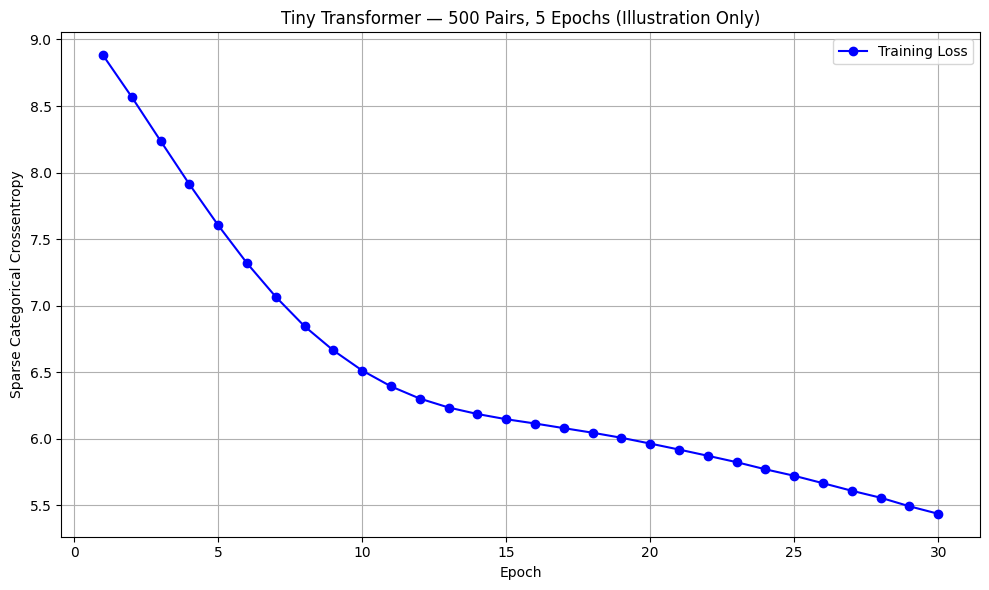

Final loss: 5.4352


In [11]:
print("Tiny model training (500 samples, 30 epochs)\n")
tiny_losses = run_training(tiny_transformer, tiny_ds, TINY_EPOCHS, label='Tiny')

plt.figure(figsize=(10, 6))
plt.plot(range(1, TINY_EPOCHS + 1), tiny_losses,
         color='blue', marker='o', label='Training Loss')
plt.title('Tiny Transformer — 500 Pairs, 5 Epochs (Illustration Only)')
plt.xlabel('Epoch')
plt.ylabel('Sparse Categorical Crossentropy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print(f"Final loss: {tiny_losses[-1]:.4f}")

# Full Training (30 Epochs, ~10k Samples)

Now we train a larger Transformer (`num_layers=2, d_model=128, num_heads=4, dff=256`) on the full 10,000 sentence pairs for 10 epochs. **GPU T4 is recommended** — this will take several minutes on CPU.

With 10k sentence pairs and this model size, translations will be rudimentary — the model learns basic word patterns and common phrases, but it lacks the scale of production systems (Google Translate trains on hundreds of millions of sentences). We are measuring whether the model learns structure, not whether it produces fluent output.

In [12]:
full_ds = make_dataset(pt_tokens, en_tokens)

full_transformer = Transformer(
    num_layers=FULL_LAYERS, d_model=FULL_D_MODEL,
    num_heads=FULL_HEADS,   dff=FULL_DFF,
    input_vocab_size=VOCAB_SIZE, target_vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN + 2, name="FullTransformer"
)

_ = full_transformer(
    [tf.zeros((1, MAX_LEN), tf.int32), tf.zeros((1, MAX_LEN + 1), tf.int32)]
)
full_transformer.summary()

Model: "FullTransformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_1 (Encoder)             │ ?                      │     1,288,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Decoder)             │ ?                      │     1,421,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_projection (Dense)       │ (1, 41, 8000)          │     1,032,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,742,528 (14.28 MB)

 Trainable params: 3,742,528 (14.28 MB)

 Non-trainable params: 0 (0.00 B)

Full model training (10k samples, 30 epochs — GPU recommended)

  [Full] Epoch 1/30  loss: 8.5155
  [Full] Epoch 2/30  loss: 7.4526
  [Full] Epoch 3/30  loss: 6.7073
  [Full] Epoch 4/30  loss: 6.2977
  [Full] Epoch 5/30  loss: 6.1204
  [Full] Epoch 6/30  loss: 6.0151
  [Full] Epoch 7/30  loss: 5.8965
  [Full] Epoch 8/30  loss: 5.7505
  [Full] Epoch 9/30  loss: 5.5804
  [Full] Epoch 10/30  loss: 5.3967
  [Full] Epoch 11/30  loss: 5.2132
  [Full] Epoch 12/30  loss: 5.0349
  [Full] Epoch 13/30  loss: 4.8671
  [Full] Epoch 14/30  loss: 4.7061
  [Full] Epoch 15/30  loss: 4.5538
  [Full] Epoch 16/30  loss: 4.4025
  [Full] Epoch 17/30  loss: 4.2607
  [Full] Epoch 18/30  loss: 4.1127
  [Full] Epoch 19/30  loss: 3.9686
  [Full] Epoch 20/30  loss: 3.8200
  [Full] Epoch 21/30  loss: 3.6763
  [Full] Epoch 22/30  loss: 3.5194
  [Full] Epoch 23/30  loss: 3.3728
  [Full] Epoch 24/30  loss: 3.2177
  [Full] Epoch 25/30  loss: 3.0701
  [Full] Epoch 26/30  loss: 2.9190
  [Full] Epoch 27/30  loss: 2.7672


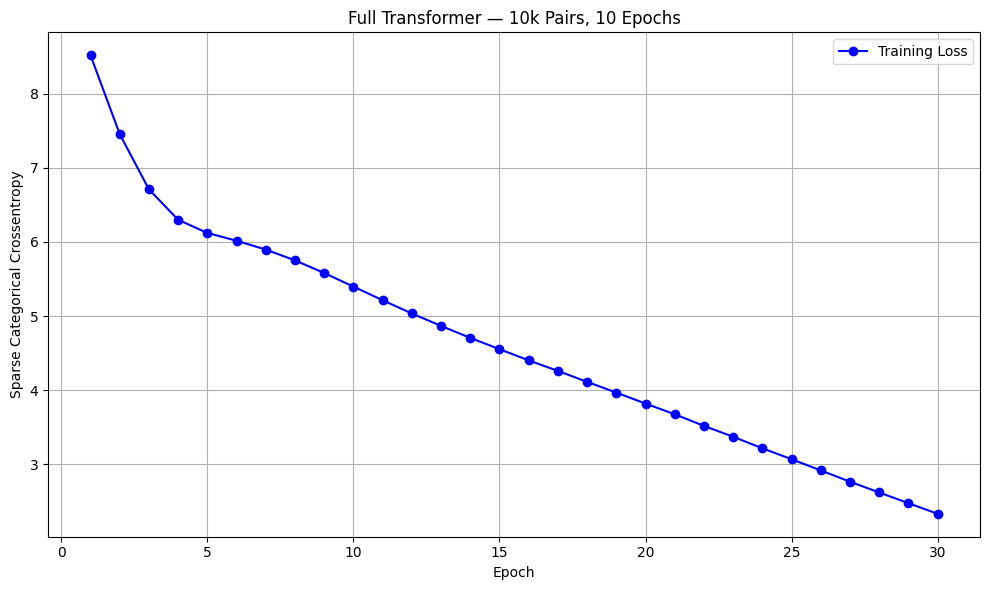

Final loss: 2.3346


In [13]:
print("Full model training (10k samples, 30 epochs — GPU recommended)\n")
full_losses = run_training(full_transformer, full_ds, FULL_EPOCHS, label='Full')

plt.figure(figsize=(10, 6))
plt.plot(range(1, FULL_EPOCHS + 1), full_losses,
         color='blue', marker='o', label='Training Loss')
plt.title('Full Transformer — 10k Pairs, 10 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Sparse Categorical Crossentropy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print(f"Final loss: {full_losses[-1]:.4f}")

**Code Explanation:**

- The full model has ~4× more parameters per layer (`d_model=128` vs 32) and twice as many layers — it can represent far richer patterns.
- `@tf.function` compiles the training step into a TensorFlow graph, giving a significant speedup on GPU (typically 3-5× faster than eager mode).
- Teacher forcing: `tar_inp = tar[:, :-1]` (decoder sees tokens 0 to T-2) and `tar_real = tar[:, 1:]` (labels are tokens 1 to T-1). The loss at each position is `SparseCategoricalCrossentropy` between the predicted logits and the true next token.

## Building the Translator Class

The `Translator` class wraps a trained Transformer and implements the autoregressive greedy decoding loop:

1. Tokenize the Portuguese source sentence.
2. Initialise the decoder input with just the `[START]` token.
3. Run a forward pass — take the `argmax` of the **last** position's logits to get the next token.
4. Append that token and repeat.
5. Stop when `[END]` is predicted or `max_len` is reached.
6. Decode the output token IDs back to words.

In [14]:
class Translator:
    """
    Autoregressive greedy decoder for a trained Transformer.

    At each step the Decoder attends to the full encoder output and
    all tokens it has generated so far, then picks the single highest-
    probability next token (greedy argmax).
    """

    def __init__(self, transformer, pt_vec, en_vec, max_len=MAX_LEN):
        self.transformer = transformer
        self.pt_vec      = pt_vec
        self.max_len     = max_len

        vocab           = en_vec.get_vocabulary()
        self.start_id   = vocab.index('start')
        self.end_id     = vocab.index('end')
        self.id_to_word = {i: w for i, w in enumerate(vocab)}

    def translate(self, sentence):
        # Step 1: tokenise source sentence → (1, MAX_LEN)
        pt_tokens = self.pt_vec([sentence])

        # Step 2: initialise decoder with [START]
        output = tf.constant([[self.start_id]], dtype=tf.int32)  # (1, 1)

        for _ in range(self.max_len):
            # Step 3: forward pass — logits shape (1, cur_len, vocab_size)
            predictions = self.transformer([pt_tokens, output], training=False)
            next_logits = predictions[:, -1, :]          # last position only
            next_id     = int(tf.argmax(next_logits, axis=-1)[0])  # greedy argmax

            # Step 4: stop at [END]
            if next_id == self.end_id:
                break

            # Step 5: grow the output sequence
            output = tf.concat(
                [output, tf.constant([[next_id]], dtype=tf.int32)], axis=-1
            )

        # Step 6: decode token IDs to words (skip [START])
        token_ids = output.numpy()[0][1:]
        words     = [
            self.id_to_word.get(i, '')
            for i in token_ids
            if self.id_to_word.get(i, '') not in ('', '[UNK]', '[START]', '[END]')
        ]
        return ' '.join(words)


translator = Translator(full_transformer, pt_vec, en_vec)
print("Translator ready.")

Translator ready.


**Code Explanation:**

- `vocab.index('[START]')` and `vocab.index('[END]')` look up the integer token IDs by searching the vocabulary list.
- `id_to_word` is a reverse lookup dictionary: integer token ID → word string.
- In `translate()`, `predictions[:, -1, :]` extracts only the last time step's logits. The model has already computed logits for all positions (thanks to the causal mask), so the last position encodes all context up to the current step.
- `tf.concat([output, ...], axis=-1)` grows the output tensor by one token each iteration. This is the "autoregressive" property: each new prediction conditions on all previous predictions.
- After the loop, `output.numpy()[0][1:]` strips the leading `[START]` token ID before converting to words.

# Translating Sentences

We pass several Portuguese sentences to the `Translator`. Given the small scale of training (10k pairs), translations will be imperfect — but common words and simple grammatical structures should begin to emerge.

> **Note:** Real production translation systems (Google Translate, DeepL) train on hundreds of millions of parallel sentences, use much larger models, and apply techniques like byte-pair encoding, beam search, and length normalization. We are demonstrating the core mechanism, not replicating production quality.

In [15]:
test_sentences = [
    "este é o meu primeiro dia.",
    "a tecnologia está mudando o mundo.",
    "obrigado pela sua atenção.",
    "o problema é muito difícil.",
]

print("=" * 60)
for pt_sentence in test_sentences:
    translation = translator.translate(pt_sentence)
    print(f"PT: {pt_sentence}")
    print(f"EN: {translation}")
    print("-" * 60)

PT: este é o meu primeiro dia.
EN: this is my day i was what is my day is my day i was living in my day i was too much is my time is my time is my time in my life is my day is my
------------------------------------------------------------
PT: a tecnologia está mudando o mundo.
EN: the world has been stuck on the world and he basically said and now who are and she knew of the world and thats just its all the world or the time in the or or
------------------------------------------------------------
PT: obrigado pela sua atenção.
EN: applause thank you to you about how we are often the way through its not its its all right now its not the way its its three or the way through how to the practice is to go out
------------------------------------------------------------
PT: o problema é muito difícil.
EN: the is it is to be here its not its about how we all its way its its that is its that is its that is its really is that is what is that is that is is is it
-------------------------------

## Conclusion & Next Steps

In this module, we completed the Transformer story — from architecture to live generation. We saw that the gap between training and inference is bridged by the autoregressive loop: encoding the source once and then decoding token by token, each prediction conditioned on all previous outputs. The `Translator` class encapsulates this loop behind a simple `translate()` interface.

The translation quality we observed reflects an honest trade-off: 10,000 sentence pairs can teach the model vocabulary and basic structure, but fluency requires orders-of-magnitude more data and larger models. Real systems also replace greedy decoding with beam search and use sub-word tokenisation (BPE or WordPiece) to handle rare and out-of-vocabulary words gracefully.

This concludes the five core modules of the course. In the **[Conclusion](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-conclusion)**, we will recap the journey from self-attention to a complete translation system, situate these ideas within the broader LLM landscape (BERT, GPT, T5), and point you toward the next steps in your NLP career.

<script type="module">
  import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@10/dist/mermaid.esm.min.mjs';

  // Find ALL generic code blocks
  const blocks = document.querySelectorAll('pre code');

  blocks.forEach((block) => {
      let text = block.textContent.trim();
      let isMermaid = false;
      let diagramCode = text;

      // Case 1: Check if the element or its parent has a mermaid class
      const hasMermaidClass = Array.from(block.classList).some(cls => cls.includes('mermaid')) || 
                             (block.parentElement && Array.from(block.parentElement.classList).some(cls => cls.includes('mermaid')));

      if (hasMermaidClass) {
          isMermaid = true;
      } 
      // Case 2: Check if the text literally starts with the word "mermaid"
      else if (text.startsWith('mermaid')) {
          isMermaid = true;
          // Strip out the word "mermaid" and any leading whitespace/newlines
          diagramCode = text.replace(/^mermaid\s*/i, '');
      }

      if (isMermaid) {
          // Create a proper div for Mermaid
          const div = document.createElement('div');
          div.className = 'mermaid';
          div.textContent = diagramCode;

          // Replace the parent <pre> tag with the new div
          const pre = block.parentElement;
          if (pre && pre.tagName === 'PRE') {
              pre.replaceWith(div);
          }
      }
  });

  // Initialize and run the render
  mermaid.initialize({ startOnLoad: false });
  await mermaid.run();
</script>
